# E-commerce Sales and Delivery Performance Analysis
## Executive Summary

This project analyzes synthetic e-commerce order data for January–June 2026 to assess sales and delivery performance.

### Key findings
- Non-cancelled gross order sales totaled USD 755,536 across 1,145 orders, with an average order value of USD 659.86.
- June sales increased by 20.24% compared with May. Laptops contributed the largest increase: USD 19,500.
- Laptops accounted for 47.55% of gross order sales.
- Of 1,043 eligible delivered orders, 722 arrived on time and 321 arrived late. The on-time rate was 69.22%, which was 25.78 percentage points below the illustrative 95% target.
- Carrier on-time delivery rates remained around 70–71% among orders dispatched on time, indicating that late dispatch alone does not explain the shortfall.
- Status updates were recorded after physical arrival for 20.81% of eligible deliveries. Among delayed updates, average reporting lag was 1.50 days.

### Recommended actions
- Review transit times, delivery attempts, delay reasons, and promised delivery lead times with carriers.
- Investigate delays in carrier confirmation and system recording.
- Obtain delivery evidence for Order 1005; retain its timing as Unknown until verified.
- Investigate declining chair sales using customer feedback, returns, inventory, pricing, and promotion data.

### Limitations
Gross order sales represent non-cancelled order value, including open orders—not collected payments or recognized revenue. The data does not establish root causes, profitability, or delivery to the correct recipient. Recommendations are proposed actions; no operational improvement has been demonstrated.

### Validation
Core sales and delivery results reconcile across Excel, SQL, and Pandas. Power BI validation remains pending.

## 1. Setup and Data Loading

This notebook analyzes synthetic e-commerce data for January–June 2026.

Required packages: pandas and matplotlib. These are available in Google Colab.

To run this notebook:
1. Upload Customers.csv, Products.csv, Orders.csv, OrderItems.csv, and Deliveries.csv when prompted.
2. Run the code cells in order from top to bottom.
3. Review the validation results before interpreting the charts.

Uploaded CSV files may need to be uploaded again when the Colab runtime resets.

In [161]:
from google.colab import files

uploaded = files.upload()

Saving Customers.csv to Customers (1).csv
Saving Deliveries.csv to Deliveries (1).csv
Saving OrderItems.csv to OrderItems (1).csv
Saving Orders.csv to Orders (1).csv
Saving Products.csv to Products (1).csv


In [85]:
import pandas as pd

customers = pd.read_csv("Customers.csv")
products = pd.read_csv("Products.csv")
orders = pd.read_csv("Orders.csv")
order_items = pd.read_csv("OrderItems.csv")
deliveries = pd.read_csv("Deliveries.csv")

print("Customers:", customers.shape)
print("Products:", products.shape)
print("Orders:", orders.shape)
print("OrderItems:", order_items.shape)
print("Deliveries:", deliveries.shape)

Customers: (300, 3)
Products: (12, 4)
Orders: (1200, 4)
OrderItems: (2428, 5)
Deliveries: (1145, 7)


In [86]:
print(order_items.shape)

(2428, 5)


## 2. Data Cleaning and Quality Checks

In [87]:
print(order_items.duplicated().sum())
print(order_items[order_items.duplicated()])

1
      OrderItemID  OrderID  ProductID  Quantity  UnitPrice
2427           16     1007          6         1        140


In [88]:
order_items_clean = order_items.drop_duplicates()
print(order_items_clean.shape)
print(order_items_clean.duplicated().sum())


(2427, 5)
0


Removed one exact duplicate occurrence of OrderItemID 16. Row count decreased from 2,428 to 2,427. No exact duplicates remain.

In [89]:
print(customers[["CustomerID", "Region"]].head(15))


    CustomerID   Region
0            1    North
1            2    North
2            3     East
3            4    South
4            5    South
5            6    South
6            7    North
7            8    North
8            9     West
9           10    North
10          11    North
11          12   north 
12          13    South
13          14    South
14          15    North


In [90]:
customers["Region_Clean"] = customers["Region"].str.strip().str.title()

In [91]:
print(customers[["CustomerID", "Region", "Region_Clean"]].head(15))

    CustomerID   Region Region_Clean
0            1    North        North
1            2    North        North
2            3     East         East
3            4    South        South
4            5    South        South
5            6    South        South
6            7    North        North
7            8    North        North
8            9     West         West
9           10    North        North
10          11    North        North
11          12   north         North
12          13    South        South
13          14    South        South
14          15    North        North


In [92]:
print(customers["Region_Clean"].isna().sum())

1


In [93]:
print(customers.loc[
    customers["Region_Clean"].isna(),
    ["CustomerID", "Region", "Region_Clean"]
])

    CustomerID Region Region_Clean
77          78    NaN          NaN


In [94]:
customers["Region_Clean"] = customers["Region_Clean"].fillna("Unknown")

In [95]:
print(deliveries["Carrier"].unique())

['SwiftShip' 'ParcelOne' 'MetroLogistics' ' SwiftShip ']


In [96]:
deliveries["Carrier_Clean"] = deliveries["Carrier"].str.strip()
print(deliveries["Carrier_Clean"].unique())

['SwiftShip' 'ParcelOne' 'MetroLogistics']


In [97]:
print(deliveries.dtypes)

OrderID                      int64
Carrier                     object
PromisedDispatchDate        object
OrderDispatchDate           object
PromisedDeliveryDate        object
ActualDeliveryDate          object
DeliveryStatusUpdateDate    object
Carrier_Clean               object
dtype: object


In [98]:
deliveries["PromisedDispatchDate_Clean"] = pd.to_datetime(
    deliveries["PromisedDispatchDate"],
    format="%Y-%m-%d",
    errors="coerce"
)

In [99]:
deliveries["OrderDispatchDate_Clean"] = pd.to_datetime(deliveries["OrderDispatchDate"], format="%Y-%m-%d", errors="coerce")

In [100]:
deliveries["PromisedDeliveryDate_Clean"] = pd.to_datetime(deliveries["PromisedDeliveryDate"], format="%Y-%m-%d", errors="coerce")

In [101]:
deliveries["ActualDeliveryDate_Clean"] = pd.to_datetime(deliveries["ActualDeliveryDate"], format="%Y-%m-%d", errors="coerce")

In [102]:
deliveries["DeliveryStatusUpdateDate_Clean"] = pd.to_datetime(deliveries["DeliveryStatusUpdateDate"], format="%Y-%m-%d", errors="coerce")

In [103]:
print(deliveries.dtypes)

OrderID                                    int64
Carrier                                   object
PromisedDispatchDate                      object
OrderDispatchDate                         object
PromisedDeliveryDate                      object
ActualDeliveryDate                        object
DeliveryStatusUpdateDate                  object
Carrier_Clean                             object
PromisedDispatchDate_Clean        datetime64[ns]
OrderDispatchDate_Clean           datetime64[ns]
PromisedDeliveryDate_Clean        datetime64[ns]
ActualDeliveryDate_Clean          datetime64[ns]
DeliveryStatusUpdateDate_Clean    datetime64[ns]
dtype: object


In [104]:
invalid_dates = deliveries.loc[
    deliveries["ActualDeliveryDate"].notna()
    & deliveries["ActualDeliveryDate_Clean"].isna(),
    ["OrderID", "ActualDeliveryDate", "ActualDeliveryDate_Clean"]
]

print(invalid_dates)


Empty DataFrame
Columns: [OrderID, ActualDeliveryDate, ActualDeliveryDate_Clean]
Index: []


In [105]:
for column in [
    "PromisedDispatchDate",
    "OrderDispatchDate",
    "PromisedDeliveryDate",
    "DeliveryStatusUpdateDate"
]:
    invalid_count = (
        deliveries[column].notna()
        & deliveries[column + "_Clean"].isna()
    ).sum()

    print(column, invalid_count)


PromisedDispatchDate 0
OrderDispatchDate 0
PromisedDeliveryDate 0
DeliveryStatusUpdateDate 0


Converted five delivery date columns to datetime, preserving the original values. No non-missing dates failed conversion. Missing dates require separate review.

## 3. Delivery Performance Analysis

In [106]:
delivery_analysis = pd.merge(
    deliveries,
    orders[["OrderID", "Status"]],
    on="OrderID",
    how="left",
    validate="many_to_one"
)

assert delivery_analysis["Status"].notna().all(), (
    "Some delivery records did not match an order"
)

In [107]:
print(delivery_analysis.loc[
    (delivery_analysis["Status"] == "Delivered")
    & delivery_analysis["ActualDeliveryDate_Clean"].isna(),
    ["OrderID", "Status", "ActualDeliveryDate_Clean"]
])

   OrderID     Status ActualDeliveryDate_Clean
1     1005  Delivered                      NaT


In [108]:
eligible_deliveries = delivery_analysis.loc[
    (delivery_analysis["Status"] == "Delivered")
    & (delivery_analysis["ActualDeliveryDate_Clean"].notna())
    & (delivery_analysis["PromisedDeliveryDate_Clean"].notna())
]

print(len(eligible_deliveries))

1043


In [109]:
on_time_count = (
    eligible_deliveries["ActualDeliveryDate_Clean"]
    <= eligible_deliveries["PromisedDeliveryDate_Clean"]
).sum()

print(on_time_count)

722


In [110]:
on_time_rate = on_time_count / len(eligible_deliveries) * 100
print(round(on_time_rate, 2))

69.22


In [111]:
target_gap = 95 - on_time_rate
print(round(target_gap,2))

25.78


In [112]:
late_count = len(eligible_deliveries) - on_time_count
print(late_count)

321


Of 1,043 eligible delivered orders, 722 arrived on time and 321 arrived late. The on-time delivery rate was 69.22%, which is 25.78 percentage points below the illustrative 95% target. Order 1005 was excluded because its actual delivery date was missing.

In [113]:
eligible_deliveries_count = eligible_deliveries.groupby("Carrier_Clean").size()
print(eligible_deliveries_count)

Carrier_Clean
MetroLogistics    355
ParcelOne         339
SwiftShip         349
dtype: int64


In [114]:
eligible_deliveries = eligible_deliveries.copy()

eligible_deliveries["On_Time"] = (
    eligible_deliveries["ActualDeliveryDate_Clean"]
    <= eligible_deliveries["PromisedDeliveryDate_Clean"]
)

on_time_by_carrier = eligible_deliveries.groupby("Carrier_Clean")["On_Time"].sum()

print(on_time_by_carrier)

Carrier_Clean
MetroLogistics    243
ParcelOne         238
SwiftShip         241
Name: On_Time, dtype: int64


In [115]:
on_time_rate_by_carrier = (
    on_time_by_carrier / eligible_deliveries_count * 100
)

print(on_time_rate_by_carrier.round(2))

Carrier_Clean
MetroLogistics    68.45
ParcelOne         70.21
SwiftShip         69.05
dtype: float64


In [116]:
on_time_dispatch_deliveries = eligible_deliveries.loc[
    eligible_deliveries["OrderDispatchDate_Clean"]
    <= eligible_deliveries["PromisedDispatchDate_Clean"]
].copy()

print(len(on_time_dispatch_deliveries))

825


In [117]:
dispatch_filtered_rates = (
    on_time_dispatch_deliveries.groupby("Carrier_Clean")["On_Time"]
    .mean() * 100
)

print(dispatch_filtered_rates.round(2))

Carrier_Clean
MetroLogistics    71.17
ParcelOne         71.21
SwiftShip         70.00
Name: On_Time, dtype: float64


In [118]:
eligible_deliveries["DeliveryStatusUpdateDate_Clean"].isna().sum()

np.int64(0)

In [119]:
assert eligible_deliveries[
    "DeliveryStatusUpdateDate_Clean"
].notna().all(), (
    "Missing status update dates: review the reporting-lag denominator"
)

In [120]:
eligible_deliveries["Late_Status_Update"] = (
    eligible_deliveries["DeliveryStatusUpdateDate_Clean"]
    > eligible_deliveries["ActualDeliveryDate_Clean"]
)

late_status_update_rate = (
    eligible_deliveries["Late_Status_Update"].mean() * 100
)

print(round(late_status_update_rate, 2))

20.81


Among 1,043 eligible delivered orders, 20.81% had their delivery status updated after physical arrival. This reporting lag is separate from physical delivery performance.

In [121]:
eligible_deliveries["Reporting_Lag_Days"] = (
    eligible_deliveries["DeliveryStatusUpdateDate_Clean"]
    - eligible_deliveries["ActualDeliveryDate_Clean"]
).dt.days

In [122]:
print(eligible_deliveries["Reporting_Lag_Days"].value_counts().sort_index())

Reporting_Lag_Days
0    826
1    108
2    109
Name: count, dtype: int64


In [123]:
delayed_updates = eligible_deliveries.loc[eligible_deliveries["Reporting_Lag_Days"] > 0]
print(delayed_updates["Reporting_Lag_Days"].mean())

1.5023041474654377


Of 1,043 eligible deliveries, 217 (20.81%) had status updates recorded after arrival. Among these delayed updates, the average reporting lag was 1.50 days.

## 4. Sales Performance Analysis

In [124]:
sales_analysis = pd.merge(
    order_items_clean,
    orders[["OrderID", "Status"]],
    on="OrderID",
    how="left",
    validate="many_to_one"
)

assert sales_analysis["Status"].notna().all(), (
    "Some order items did not match an order"
)

print(sales_analysis.head())

   OrderItemID  OrderID  ProductID  Quantity  UnitPrice     Status
0            1     1001          1         2        750    Shipped
1            2     1001          6         4        140    Shipped
2            3     1001         10         2          8    Shipped
3            4     1002          4         3         25  Cancelled
4            5     1002         11         4         48  Cancelled


In [125]:
sales_analysis["Line_Sales"] = sales_analysis["Quantity"] * sales_analysis["UnitPrice"]

In [126]:
non_cancelled_sales = sales_analysis.loc[
    sales_analysis["Status"] != "Cancelled"
].copy()

In [127]:
gross_order_sales = non_cancelled_sales["Line_Sales"].sum()
print(gross_order_sales)

755536


In [128]:
non_cancelled_order_count = non_cancelled_sales["OrderID"].nunique()
print(non_cancelled_order_count)

1145


In [129]:
average_order_value = gross_order_sales/non_cancelled_order_count
print(round(average_order_value, 2))

659.86


### Monthly Sales and Growth

In [130]:
print(orders["OrderDate"].dtype)


object


In [131]:
orders["OrderDate_Clean"] = pd.to_datetime(
    orders["OrderDate"],
    format="%Y-%m-%d",
    errors="coerce"
)

In [132]:
invalid_order_date_count = (
    orders["OrderDate"].notna()
    & orders["OrderDate_Clean"].isna()
).sum()

print(invalid_order_date_count)

0


In [133]:
non_cancelled_sales = pd.merge(
    non_cancelled_sales.drop(
        columns=["OrderDate_Clean"],
        errors="ignore"
    ),
    orders[["OrderID", "OrderDate_Clean"]],
    on="OrderID",
    how="left",
    validate="many_to_one"
)

assert non_cancelled_sales["OrderDate_Clean"].notna().all(), (
    "Some non-cancelled sales rows have no valid order date"
)

In [134]:
print(non_cancelled_sales["OrderDate_Clean"].isna().sum())

0


In [135]:
non_cancelled_sales["Order_Month"] = (
    non_cancelled_sales["OrderDate_Clean"].dt.to_period("M")
)

In [136]:
monthly_sales = non_cancelled_sales.groupby("Order_Month")["Line_Sales"].sum()
print(monthly_sales)

Order_Month
2026-01    134137
2026-02    117346
2026-03    123202
2026-04    104326
2026-05    125556
2026-06    150969
Freq: M, Name: Line_Sales, dtype: int64


In [137]:
monthly_sales_change = monthly_sales.pct_change() * 100
print(monthly_sales_change.round(2))

Order_Month
2026-01      NaN
2026-02   -12.52
2026-03     4.99
2026-04   -15.32
2026-05    20.35
2026-06    20.24
Freq: M, Name: Line_Sales, dtype: float64


### Product Sales and Contribution

In [138]:
print(products.columns)

Index(['ProductID', 'ProductName', 'Category', 'ListPrice'], dtype='object')


In [139]:
product_sales_analysis = pd.merge(
    non_cancelled_sales,
    products[["ProductID", "ProductName"]],
    on="ProductID",
    how="left",
    validate="many_to_one"
)

In [140]:
product_sales = (
    product_sales_analysis.groupby("ProductName")["Line_Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(product_sales)

ProductName
Laptop         359250
Monitor        115500
Desk            78120
Chair           53340
Headphones      31915
Webcam          29370
Backpack        25872
Keyboard        21600
Lamp            13920
Mouse           11675
Storage Box     11110
Notebook         3864
Name: Line_Sales, dtype: int64


In [141]:
product_sales_share = product_sales / gross_order_sales * 100
print(product_sales_share.round(2))

ProductName
Laptop         47.55
Monitor        15.29
Desk           10.34
Chair           7.06
Headphones      4.22
Webcam          3.89
Backpack        3.42
Keyboard        2.86
Lamp            1.84
Mouse           1.55
Storage Box     1.47
Notebook        0.51
Name: Line_Sales, dtype: float64


### Regional Sales

In [142]:
regional_sales_analysis = pd.merge(
    non_cancelled_sales,
    orders[["OrderID", "CustomerID"]],
    on="OrderID",
    how="left",
    validate="many_to_one"
)

print(regional_sales_analysis.head())

   OrderItemID  OrderID  ProductID  Quantity  UnitPrice     Status  \
0            1     1001          1         2        750    Shipped   
1            2     1001          6         4        140    Shipped   
2            3     1001         10         2          8    Shipped   
3           11     1005          5         2        180  Delivered   
4           12     1005          4         1         25  Delivered   

   Line_Sales OrderDate_Clean Order_Month  CustomerID  
0        1500      2026-01-20     2026-01          77  
1         560      2026-01-20     2026-01          77  
2          16      2026-01-20     2026-01          77  
3         360      2026-05-01     2026-05         236  
4          25      2026-05-01     2026-05         236  


In [143]:
regional_sales_with_region = pd.merge(regional_sales_analysis, customers[["CustomerID", "Region_Clean"]], on="CustomerID", how="left", validate="many_to_one")
print(regional_sales_with_region)

      OrderItemID  OrderID  ProductID  Quantity  UnitPrice     Status  \
0               1     1001          1         2        750    Shipped   
1               2     1001          6         4        140    Shipped   
2               3     1001         10         2          8    Shipped   
3              11     1005          5         2        180  Delivered   
4              12     1005          4         1         25  Delivered   
...           ...      ...        ...       ...        ...        ...   
2316         2423     2198          2         2        220  Delivered   
2317         2424     2198         11         3         48  Delivered   
2318         2425     2199         10         1          8  Delivered   
2319         2426     2200         11         2         48    Shipped   
2320         2427     2200          3         1         45    Shipped   

      Line_Sales OrderDate_Clean Order_Month  CustomerID Region_Clean  
0           1500      2026-01-20     2026-01       

In [144]:
regional_sales = regional_sales_with_region.groupby("Region_Clean")["Line_Sales"].sum().sort_values(ascending=False)
print(regional_sales)

Region_Clean
North      230200
East       216034
South      182023
West       123389
Unknown      3890
Name: Line_Sales, dtype: int64


In [145]:
print(regional_sales.sum())
print(regional_sales.sum() == gross_order_sales)

755536
True


### Customer Sales and Order Value

In [146]:
top_customers = regional_sales_analysis.groupby("CustomerID")["Line_Sales"].sum().sort_values(ascending=False).head(5)
print(top_customers)

CustomerID
277    10802
108     8889
166     8714
251     8542
42      8447
Name: Line_Sales, dtype: int64


In [147]:
customer_summary = regional_sales_analysis.groupby("CustomerID").agg(
    Total_Sales=("Line_Sales", "sum"),
    Order_Count=("OrderID", "nunique")
)

print(customer_summary.sort_values("Total_Sales", ascending=False).head(5))

            Total_Sales  Order_Count
CustomerID                          
277               10802            7
108                8889            6
166                8714            8
251                8542            7
42                 8447            4


In [148]:
customer_summary["Average_Order_Value"] = (
    customer_summary["Total_Sales"] / customer_summary["Order_Count"]
)

print(
    customer_summary.sort_values("Total_Sales", ascending=False)
    .head(5)
    .round(2)
)

            Total_Sales  Order_Count  Average_Order_Value
CustomerID                                               
277               10802            7              1543.14
108                8889            6              1481.50
166                8714            8              1089.25
251                8542            7              1220.29
42                 8447            4              2111.75


In [149]:
print(customer_summary["Total_Sales"].sum() == gross_order_sales)
print(customer_summary["Order_Count"].sum() == non_cancelled_order_count)

True
True


### Product Contributions to June Growth

In [150]:
monthly_product_sales = product_sales_analysis.pivot_table(
    index="ProductName",
    columns="Order_Month",
    values="Line_Sales",
    aggfunc="sum",
    fill_value=0
)

print(monthly_product_sales)

Order_Month  2026-01  2026-02  2026-03  2026-04  2026-05  2026-06
ProductName                                                      
Backpack        4704     2784     4416     3648     4224     6096
Chair          11480     8820     6720     8540    10360     7420
Desk           16380    15300    10800     9720    11160    14760
Headphones      6825     4810     4940     3965     5980     5395
Keyboard        4500     3960     3960     2970     2925     3285
Lamp            2310     2310     1740     2550     2580     2430
Laptop         58500    54000    63750    48000    57750    77250
Monitor        20020    15400    17600    17380    20240    24860
Mouse           2200     2400     1750     1775     2150     1400
Notebook         640      720      552      608      608      736
Storage Box     2068     1672     2354     1210     1804     2002
Webcam          4510     5170     4620     3960     5775     5335


In [151]:
june_product_change = (
    monthly_product_sales[pd.Period("2026-06", freq="M")]
    - monthly_product_sales[pd.Period("2026-05", freq="M")]
).sort_values(ascending=False)

print(june_product_change)

ProductName
Laptop         19500
Monitor         4620
Desk            3600
Backpack        1872
Keyboard         360
Storage Box      198
Notebook         128
Lamp            -150
Webcam          -440
Headphones      -585
Mouse           -750
Chair          -2940
dtype: int64


In [152]:
print(june_product_change.sum())

25413


June gross order sales increased by USD 25,413 (20.24%) compared with May. Laptops contributed the largest increase (USD 19,500), while chairs had the largest decrease (USD 2,940). Further investigation is needed to explain these changes.

## 5. Validation Checks

In [153]:
assert gross_order_sales == 755536, "Sales total does not match"
assert non_cancelled_order_count == 1145, "Order count does not match"
assert len(eligible_deliveries) == 1043, "Eligible delivery count does not match"
assert on_time_count == 722, "On-time count does not match"
assert late_count == 321, "Late count does not match"

print("All baseline checks passed.")

All baseline checks passed.


In [154]:
assert monthly_sales.sum() == gross_order_sales, "Monthly sales do not reconcile"
assert product_sales.sum() == gross_order_sales, "Product sales do not reconcile"

print("Monthly and product sales checks passed.")

Monthly and product sales checks passed.


In [155]:
assert regional_sales.sum() == gross_order_sales, (
    "Regional sales do not reconcile"
)

assert customer_summary["Total_Sales"].sum() == gross_order_sales, (
    "Customer sales do not reconcile"
)

assert customer_summary["Order_Count"].sum() == non_cancelled_order_count, (
    "Customer order counts do not reconcile"
)

assert june_product_change.sum() == (
    monthly_sales.loc[pd.Period("2026-06", freq="M")]
    - monthly_sales.loc[pd.Period("2026-05", freq="M")]
), "Product changes do not reconcile to June sales growth"

print("All additional reconciliation checks passed.")

All additional reconciliation checks passed.


## 6. Visualizations and Insights

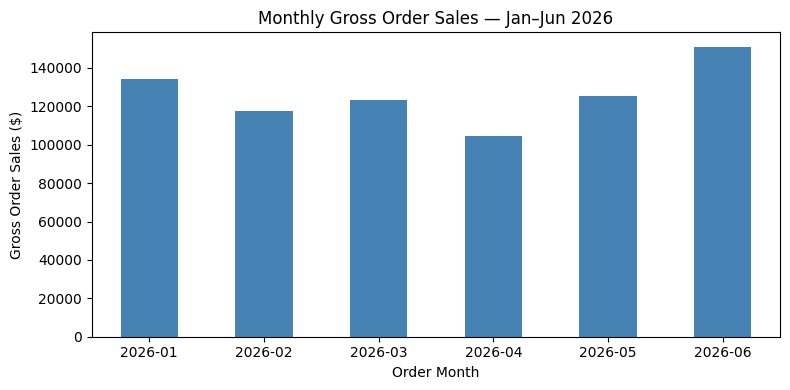

In [156]:
import matplotlib.pyplot as plt

monthly_sales.plot(kind="bar", figsize=(8, 4), color="steelblue")

plt.title("Monthly Gross Order Sales — Jan–Jun 2026")
plt.xlabel("Order Month")
plt.ylabel("Gross Order Sales ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Gross order sales peaked in June at USD 150,969 and were lowest in April at USD 104,326. June sales increased by USD 25,413 (20.24%) compared with May.

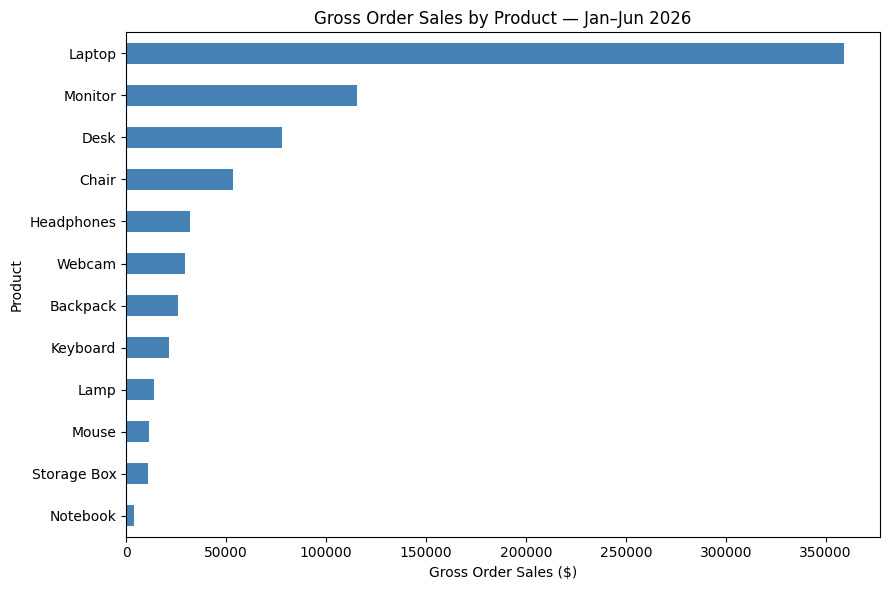

In [157]:
product_sales.sort_values().plot(
    kind="barh",
    figsize=(9, 6),
    color="steelblue"
)

plt.title("Gross Order Sales by Product — Jan–Jun 2026")
plt.xlabel("Gross Order Sales ($)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

Laptops generated USD 359,250, contributing 47.55% of gross order sales. Monitors ranked second at USD 115,500 (15.29%). These figures measure dollar sales, not profitability.

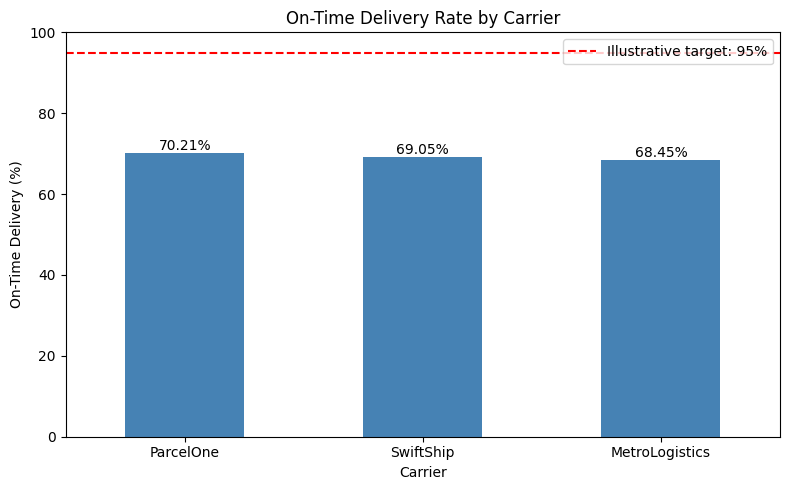

In [158]:
ax = on_time_rate_by_carrier.sort_values(ascending=False).plot(
    kind="bar",
    figsize=(8, 5),
    color="steelblue"
)

ax.axhline(
    y=95,
    color="red",
    linestyle="--",
    label="Illustrative target: 95%"
)

ax.bar_label(ax.containers[0], fmt="%.2f%%")
ax.set_ylim(0, 100)

plt.title("On-Time Delivery Rate by Carrier")
plt.xlabel("Carrier")
plt.ylabel("On-Time Delivery (%)")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

On-time delivery rates ranged from 68.45% to 70.21% across the three carriers, all below the illustrative 95% target. ParcelOne had the highest observed rate. These differences alone do not establish carrier fault; dispatch timing, transit conditions, and promised delivery lead times require further investigation.

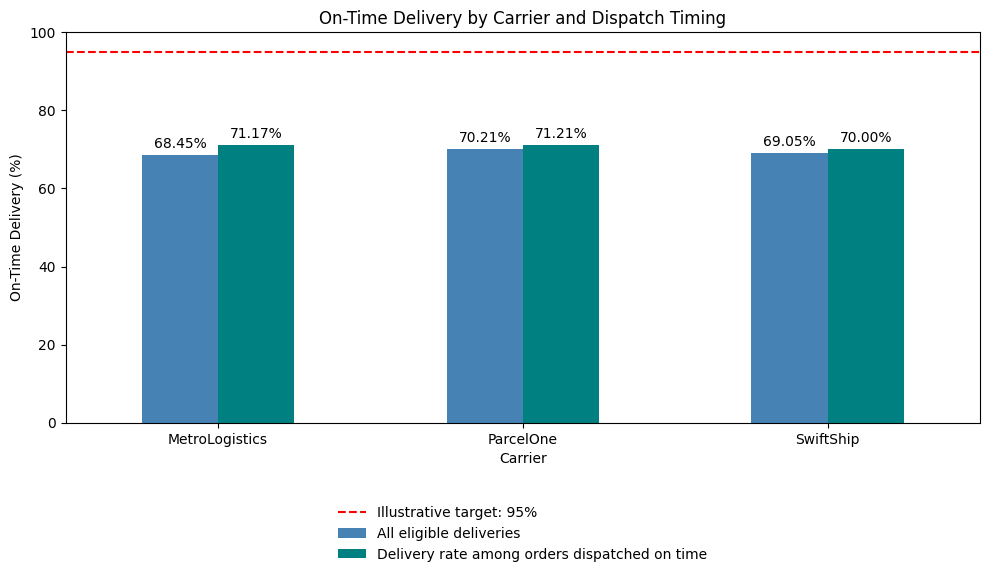

In [159]:
carrier_comparison = pd.DataFrame({
    "All eligible deliveries": on_time_rate_by_carrier,
    "Delivery rate among orders dispatched on time": dispatch_filtered_rates
})

ax = carrier_comparison.plot(
    kind="bar",
    figsize=(10, 6),
    color=["steelblue", "teal"]
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

ax.axhline(
    95,
    color="red",
    linestyle="--",
    label="Illustrative target: 95%"
)

ax.set_ylim(0, 100)
ax.set_title("On-Time Delivery by Carrier and Dispatch Timing")
ax.set_xlabel("Carrier")
ax.set_ylabel("On-Time Delivery (%)")

plt.xticks(rotation=0)
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    frameon=False
)

plt.tight_layout()
plt.show()

Among orders dispatched on time, carrier on-time delivery rates ranged from 70.00% to 71.21%. Late dispatch alone does not explain the delivery shortfall. Further investigation should examine transit conditions, delivery attempts, and promised delivery lead times. This comparison does not establish causation.

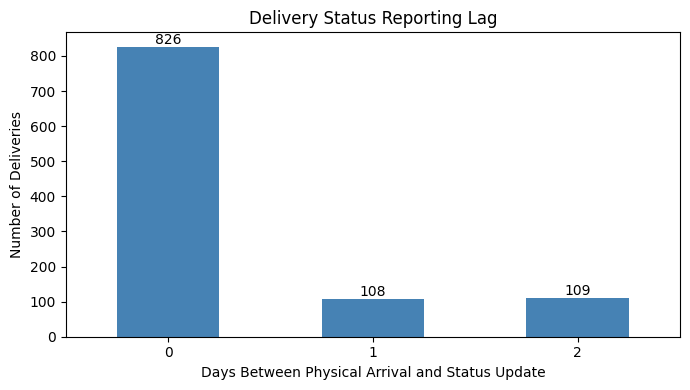

In [160]:
lag_counts = (
    eligible_deliveries["Reporting_Lag_Days"]
    .value_counts()
    .sort_index()
)

ax = lag_counts.plot(
    kind="bar",
    figsize=(7, 4),
    color="steelblue"
)

ax.bar_label(ax.containers[0], fmt="%d")

plt.title("Delivery Status Reporting Lag")
plt.xlabel("Days Between Physical Arrival and Status Update")
plt.ylabel("Number of Deliveries")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Reporting Lag Insight

Of 1,043 eligible deliveries, 826 had same-day status updates, 108 were updated one day later, and 109 two days later.

Overall, 217 deliveries (20.81%) had delayed updates. Among delayed updates, average reporting lag was 1.50 days. This measures recording timeliness separately from physical delivery performance.

## Business Recommendations

### 1. Investigate Physical Delivery Delays

Operations should review late deliveries with carriers, compare actual transit times with promised delivery lead times, and request delay reasons and delivery-attempt records. Use the findings to identify corrective actions and monitor on-time delivery performance.

### 2. Improve Status Update Timeliness

Operations should investigate delays between physical delivery, carrier confirmation, and system recording. Agree on an update timeframe with carriers, address the identified delays, and monitor reporting lag separately from physical delivery performance.

### 3. Resolve Missing Delivery Evidence

Operations should request proof of delivery and the actual delivery date for Order 1005. Correct the record only when supported by evidence. Until the date is verified, retain its delivery timing as Unknown and exclude it from the on-time delivery calculation.

### 4. Investigate Declining Chair Sales

Sales management should investigate the USD 2,940 decline in chair sales from May to June by reviewing customer feedback, returns, stock availability, pricing, and promotions. Use the evidence to decide whether product or commercial changes are needed.

## Limitations and Additional Data Needed

### Synthetic Data and Proposed Actions

This project uses synthetic data. Recommendations are proposed actions; no real operational improvement has been demonstrated.

### Meaning of Gross Order Sales

Gross order sales represent non-cancelled order value, including open orders. They do not represent collected payments, recognized revenue, or profit.

### Delivery Root Causes

The available dates identify timing patterns but do not confirm the causes of delays. Obtain carrier tracking events, delay reasons, delivery-attempt records, and route or service-level information to support further investigation.

### Inventory and Sales Drivers

Inventory availability is not included in this dataset. Obtain stock levels and stockout history to investigate whether product availability contributed to sales declines. Customer feedback, returns, historical pricing, and promotion data are also needed to investigate other possible explanations.

### Delivery Evidence and Recipient Verification

Order 1005 lacks an actual delivery date and remains an unresolved exception. The available fields also cannot verify whether orders reached the correct recipient; additional proof-of-delivery information is required.